# Практика 6. Как восстановить пропущенную связь между странами?

В историческом графе **Nations** сохранены тройки вида (страна, отношение, страна). Закроем последний элемент и попросим две модели из лекции 6 расставить страны по баллу правдоподобия. В конце откроем конкретную тройку с отношением `embassy` и посмотрим, как фильтрация меняет место ответа.

Запустите все ячейки по порядку. Нужны Python, PyTorch, pandas и matplotlib. Данные встроены в блокнот, обучение идёт на CPU. Все оценки относятся к записям в Nations; дипломатические отношения с тех пор менялись.

In [1]:
#@title Встроенные данные (выполните без изменений)
# Встроенная копия исходных таблиц. Выполните ячейку без изменений.
import base64, gzip, io
payload = {}
payload['train'] = (
    'H4sIAAAAAAACE5Vd23bbSA58dr5m43wR42gyXNpSjmhnJ/v1K7FvVYVCy/syJ2NJZF/QuBQK6PPp/e/T9XU5/9if3tbX9X25/lle'
    'X9fl/HJ6+ti+nH7++fX+tJ7fT9efl9+X68/929PHvnz59+X6Yzk/XU+v3y+X7f26nPfX5X29nPfj41+X+yOf3te3077eHvWf5Xr7'
    '+3798rE9nU8/b9/8ffp++nv5vV7qB/UXtwfiy+5DuD3v6T+n9eff76cfH+ffl/fTbTw/1uXLy9/reXlaXl5u37i/uv759oqPs/zg'
    'mEZ7x+nt+7Lvf24D6XNv83m5vL1dzt9fLy9fy7BePr4vYVC391zOt4kt8WfPT+t+XU6v91HEVSufyVuOEZ9/XsrXvl+X/66vX/or'
    '6Mv30Rzr4aYA/346/fPrcn2/v7Ws3+nlcr68rS/L+qMNsOys3b0yBl3026PqB7f1qC+4//FYdS8J5eW0djjiY41+nH6dbv+5y9sx'
    'vTKu2+Per6fbc07707HPdbej8JR33NbvqWzv/akycnxnGa0uN64dLvjY6ftL7n/bfl329T69+8j/qSJX97XtSh1I2O3nKodliu3b'
    'dQginMdafP+4vi32TGy0CTss2/7+cVvNsjV1v/TXiXAdyzw+6zJUP+A5xjUNgnqcHZx9XZd6btfbME9vf1DiZAHr6Tqd3tafN7mi'
    'mfKcyiG6/PXX+rIur7/X2xbtfRv6jEgdyQTqVz7O94csr8vLO50FPf+HROzXYxfgbLUZ3mfOx7/sfFvEfjxvb/Cy969x2O+yXX9+'
    'LHSii8YkVGBwqkWkZKXKDutZRWW0kqIt328S+8+v0+uP9dfr5W1RYbwPnQSuS+d45flyvp3k19tfM4tQH/7yR85jUAZtYxbWK5mW'
    'tFalma7Lx3Xd38pQqhDcZyP6q32tKlV8+jH3rt27XagbiiZMhKjsNT4qUa5lX7pU3+z2H1q6rkuOtS6bYqzvIgqpbc1+NSasjJgN'
    '+zZb1XokyivUpJTloc1qWvz+ep4angFUNrglx8nr2v02sqpD3GGsH9Fc6i7RWRridyxumQkPjU5YERb+wnGYUe+e/zpd7/Pdh9eC'
    'cypjM0cS31RGQs4HnQ8UqvZAMBx3kdpZMeEQWJfFHao/iV5Cdwjq6RdXiI/QbZjtDOHfqwSjPqzCIodlHPkmvrwG3Yso82xKOz9O'
    'uJx10arrAVJV5z7mWG3d2NUx2mCpju+20ZZhlTd0B/xl+GJDZmaOdtM19X+Dqibpeg47gPJQFjSKVl2LtkhjpmTV3bqKJgPXERRo'
    '8babOpzIS9m/sKjWtb4HHPcffL/8ebm8v9/X/Er7Nb582EV/dsnHUxvQBXUsCLuxbK17cBBCFNEQ5CJEse/64TY7jIDK80X/i60Z'
    '5qfOKdcwh9zIzI6lM64w+maptkh+Z8Os6n1UNd0M133TnLlVJ5c/gwENTRj3v4kXqPwSX+SWKDcEFJA1Z/94zTHdGG7f5bWuUz0W'
    '3zIvvmozI0fTAPL+tMMBzOznsQBd06meoHUsQ6iDC1LSjGs93rhizSzsi8Zaq3U7graqazk2UpagftCjpyHw1dFpZwt9Ddmh47DE'
    '6LT8nczS5rVGnWF7/fD+5CTX/dIHf4XpiTqiR2G4Nzzm4KmWL4u3qu98bipziXOp+xl1zbF4uP1lAVH4uw0umzCwI1iZOnanH8pC'
    'Sshi3kJDRu+FHdvhzAMw008LqRlGuu6j5bAcAhNYDPogHK62Byh7dLTrB+2cskthcKr+IJHXYy/H6E0Em3i5A0dBkYHzM7UXMoYR'
    'JnIUX6Oi5pV9zurzYIKP+JUOr5UHDoL6JtdHufBkd2rAAivNjvHy0Fnz2GeGAIyN+PXrehvQPkANUlnj6N+XlIJ2wjOGZwwBLUg0'
    'CdsmsRRjMrAZ3RQ5ryngf8Xr87PsRg9UXJ9jd+ZmgsJW5xuI11T8x0uaiAezOgLD1SJyKYJYflcWmB2y8iwC/IpNFFOqHnoPVZy3'
    'hFhyqpRIEfZzWX3NopCiB+fByPbaPYQ0h+ZlDDHz176hEpPAWVBJiccXZ1J7RB3Opwkrad2aq1zd0W64QPU6T1ACxMwJDKoxh+xg'
    'Pci2lsFGjLz4jk04h1Ow+3wIRgTBDwVHJ0HYRvg7BuD91Ag9WoRxaJU+9K5WQKdFSQZZE+0VT3fNI9S9HdZnuE203zYmSdHzoZ/M'
    'fpG2BnjNmd3oCEJoEo+2LuixecMa1G+3AzHCih3cmJFHGNgheoV6Bg1iiz4/LkCG2d3NS5hojSiid1XFmGxB89AJoOw+d4Zo8Omt'
    'LnadstjtoQkMwlojGT0esLeQkYreZf/BDIlpkUESbzc7X86ixxNMdAYY5gTsD+uaqyqI2/r5IRAXVEQNmdtfpvGl+DEeVjYIRpOC'
    'AEUJwkISVs6YSS3pECUMKZOPMXVLdlu8o0uvClZMnIORGcnXhvaVh/z4uJaATJNJbG62HC0ZJtCI333S/RVdEzBC1Q9EjAMFJLlj'
    '7B2S1ED+gOqyHGuHrywOCuhcd2IQsK2aOfhluCZkNe3JWeJzaOwCM7bv22ybTxP0pbHQPXmB7enBfoPvQCB89z4tSBizTnahawAl'
    '+IKJe2KCeHl/X142A9NvNgCWhPOgY3A4FhzLjihvWfRrsjVImKh/MpJYXsaIgM8jG4qHSEHTEMGLi3hWR2UM7F72A2AZSRpM8NYJ'
    'S2KSz6N8UaaWrUV1qcmqJOD0VsIKBCVbprQfLf0zI4HBCsphfh7HzwABVjMH9zXLzRszFQCOkOyKUGhd3sn2oNl3eRIB3yi1gahI'
    'XTnO5O+LdbtKlLo5eLgjN+oZIKZRDHOPKdSYe3gV8vLOcZOkUxt+nw9xCgYi4vJX/TfIt5EE0r9YHR6LNCZIeBW9fGTVqvRmwbVb'
    'l4IpNM01pK3raPKKPUieABoYK4dwxoDjZTuOAWUuT9cJUUg2kwhIdn2xDmo1aVW4yZBHk+HVhnWGDcSY5ITF9zLJnYWFPtrbgLlb'
    'DF0BtK8R1ku5eIrsmERm+/QdDK4xc+vUfAjCBx4vszVJXkkldW/PcX9yGAnDzSmgTNj20Gtje2DMxm20bJbPyFUfYP20xtEt419d'
    'Q0lc1WnH5D54vpOxdJNLOJ+DqgOXokIPW4bW3bPPyOPLXPgq/Ybehn46Qj4+9Wce7dBGE6JrPoehWOFtkQ6w+JnShGycYLlWyHhp'
    '46wPkZ11CnOMCd9oHFq0uYID2/C7SDSc/sDbsGAoaiVKSey5RQ/x2WSho1Wd8s0NHMpUaFmBOSzt0mSGA0hG4HiFl5aI2taJ91gz'
    'JEUa94FPCEKYhJJ0Jw2znhAOhuXtMBynBwaBxYLxfV+RytPYsPVPTIJx5sjECATV1Wgg8WVJ2XKkCHipYR8L1VixFWJ+dP9ScPvg'
    'ESIMFOgjWzCguq3jANjwItJ51NGDUaFeqL5KfV1HcRgAIHpCFN62t2gaF6EawP7bLMam2V/nCisYD8LltoeIzzfZJ9XlkTdIAETn'
    'VanZITyjRJ11gZfIlPYHLCRXO0Dvk3EG447QM6ObSm9YF2+Oxi8cPsEpSgCibO2CV3vlVHzKV4rwoQMq2LaQWRqPGqho1zTGcjQP'
    'VywvGgSnMyPeS4x4XvsEKaEoRxLDfXK+PEfzNlggI3zXohNCNNJwkQhyaqrIZPCEcDwG7DwEDE9jFgYo1z69jNGAwqiDuPDpNDMm'
    '3tmASkyV1lsM8u9QiLyaTvHch5oxBDCFLOEArlkWVguljZOcyLwK1A+f2wnYhNPViO1TqhLynapP5D1BtKOgJSRt53JvfcpsaNBV'
    'GtlBK9sOb/BqSgOWQOGyBWfigGianoK+obQnAaJUV47JBlqaQumbzcXDbAKBvD6ha1VCQbhWxp5j9kR07s7XJBYa5aVaTBqz9REs'
    'kqx5CPaC0cuK7sxw9hQyN3iRD9NHgjjmXCfhtKIIqTOwejpNbhAXTBtFMRa7/yBbNEC/zPVYuawCTytxRY0HYHK1D6s1gx5O04ke'
    'jwV7DlmmmC9gsmFw8pSegzhUUgdNIeRjgld/lTpINtBpuWq7g4lxAC/YSItxjw0d2RY0cNkSREZMIo7MFxKYlN++PSCaLln978b6'
    'lip5CXdSAxuVjiRikwjXF5JrgodJMoSkQvYgIaokCA25pgGzA+5ogo9kVbAOlcz84sio2BwaPwN8gSMVHOCQuAuUspjCwcpTYcXm'
    'HufAlme/SYPVqnaNU5OHa6YbATkXmG4zFnOrgMLQ3tYP6ynbEZZuj0uTR5QeqzanNgI0gfoDiIApDuuOXechuVp2qSRkrjQ0xGBq'
    'DddWEbyiyj7WXiIizL+NUCXSOFKC2pbQi4qaZ+QrcKMBLsxrG1vcLFmpNovmHQakJSa9UFhBYU0waoSYie23Gw8fR/IJCFErMMEq'
    'Oeol1yOwrwm0duOB8VRcscqDIkNOqWbEG5JLoJGASieHMGUZRh/HEKhi9BXzZxDPW7YfFdYaN1PRysTl9xTDTerRHqhgz2JsrxDM'
    'SF2HkNnX7iDGOyfWd16uSzktJPymJUm2NGPzrRea0gXbh0bE0GtsEvuAdowF8E06pECZcUXTSAcRHCOJEbQboalSszjwRtIYo/uO'
    '+RKKYsSrbrYjcb+OWcxRjikhhRBlF0SapEOSnZ3UKVAvDnuwhJqaEu9K6J4rG0OJImTS5P8FBZJUyWB+MlZk0PtATm6/7Zz5GeV4'
    'txzEb7HKAzA0p/GYPxdTpxnpaVRm84PIlgLlkPW0oND4mkwP8ZY/BNKivlUnU4Ko41CaBJnk86V6Lta4KtOj0f5c7GgzFf28kSNH'
    'e8o4vGXHjDOhEC9o6XDWCUfw3qqJ/CFOISxFSAMMR3IV8OIZ9B4OTeIu2ZdIyopphyxXAtCQKFi7D9S3KXCFE2yIQXzjtVaQkqsZ'
    'upY2zO9QiIJp8lCulq8nMW79hzZBoiihVvpk6KL4zAK8SJopJBbQPZ/wVHsGwbB2SRicAaxHKXgo5O6i9+Zr3IxrFDB6U+CWIYaa'
    'dVXGdji4zgG2zDKaXiyy8Z3pXOEpT08NoGNksCdmqkgnybZIkgqZotTtQLmehCVHYh7OEtahaSmh9kHsOOIngE+H+AsYS/V7iWed'
    'gV6faEb3aLUhLe18Jq1zyGIK24NN+l3MerlkDkqSc+KeayZKIe8cAIIMBAzx9wjTvzGVJJDFJE7LeeSmfRADxa4MLuOKq1lxvYye'
    'fek+wEdJ6X2KK2p/p68DX8qh4NPUa8ySYWoEOy5wixBvY/oJw3Xlxt2bKYYT3Jk9yY46XSV0xlhItSSRhPNFIgZpNjTgElxRXfzX'
    'gldhDxcyYUZJpq0joUtkEZ/Xy37zSK7X9f1y/TMFwmxvHG5yOWtAOpbR4VSbaTMDySPDUnSw5f5pwLtLTPBfYgyilGilqEtlIcJ0'
    'D/v/2QqApJi1BWYKP0bxd462Qb43n/Xglj2yHy7fg+cpaUUTxoyZSoNVB9JqMAht/3pvzIHuGi4d6tgkmVRxlkkpnEWYsuT6FC7B'
    'GJApk7POozFiYpTed/o0LXZHiPOwqaiDpasMPOx+ksT8SfrHw3ib736qvE5A+GxWY1PDb2B9Q0VKIs1egpDVYXEbuk80381I4Q4f'
    'f3a5Qe2KI/3whq3sgIc9BB5haO3t2juy9rbjEQZCSIodNsN4Bz/GNSLGENMLBfkBvgnGNPFLzIgAFUWeke9bu5G2lhqvyNNOcQ0g'
    'HtsS6Ly1ui2EQyuqepk1Q8yfmsQmczz8iw6tqz2zlaAK6j+cDcdl25L2maKYBR0UrlGv+DFweV6mDMlN29k20Ks3RznBpIxpBJzV'
    'C7M9l24SpjE+JPKVOL5NElrOQ03L7rr/FVkohm+oYUrsY2N1AtUuTstsmRQAlMXQNksgZFsRB8VKxzNtk0GIuLQVFgg4z9vtq6Gv'
    'CB8ZA4EE73MGQsLN+h7fXzRBy/uRiwQG26EigQ6lT5P0OmSPP2kQ59M8nbdiGnDu6YHq9XZSCZfQ+1wWA6h5tkjQphmQzAaaVsPT'
    'ngIx+Sgi2AZ4GdUBYbqOnjLeoBrT5i0rSJ3nhm1ha9K9NUlX9r52bmadegLWEYIyWhlq5GVwk04W9kbUqtWkz2YHSMR+YvWFbXJJ'
    'eFTWhX8LNYyBIBVqgwYBxQJjz3m7uIf9k2HpQ58I54BPeP3d0afA2qbjpREEGoKq871QmvMTW2/FnxL4mBF9wcxsvrWudhYCNMXg'
    '5Ylej1zrrAWvFrq5FNfmGk5/MlM5ps7UtX3J7mcxoWoWQdbFZmwKy7VFr7pWu7y+1jU+5puNwYBJPj3NCX8h9HajTRkiLkfSHg7R'
    'E8SUvQlcJy2YXGdC186dju70vh/m9muTiW7nuD6FXBbTUBUrQhLUIEL5FgtOr3fSPGeWl1BzLLFumhqZ1WyEPk87IRZ5SRjI/PxT'
    'G2X6ziCzpK53q2w8mhD+0cwZokheWz5D9TdXgeNPrzZ33B83htuk3RHxjyL9wFEhsKv6pBqTEr9Z9ZojPqDHHMqJE1ATbhIKbBhM'
    'PzGlISNvCeyRd8uM/RMn1zUIdV/tVKgtdFWfIbx8cEOMUaDZ9QgWktQK9DNQOdzo5+VPm3CktLbX3WrGwBbxgRG7TyCOrOglFGgI'
    'YCJqOTdZ9mYq9NJcM2ZPHv0qXITEs5t1NOpVf0zNhT+YulvTpsV3cTfGz3cEDtzf56ROIDCCXR/djtKpt5ymL/0lnaOOW8zDMrcO'
    '4f6RpBHNrJkqqhBzPwWnRSYKBdGX+HJtokGHBjwwo5BYVT1unRRyZdHTMY1q5lfkPG4qjXeJSg/rCNM9CkkkKZqhxk6jR8jFlfq5'
    'SuK8P3OWXnF4fUixGFvhRNSQnweDA6t69ljeR1CNbQ3HxCrx9NME2ogpqbtzuJ8KyJtJEQT+Xi5JWGKxZPAuNrtxcWP1eOW9kuD4'
    'TSo7bBPw/FLR0LpRb5vcHhVxNK8oegKHekmRw8F+imlXR8AHZrFqqhRP25TSl9yAq804OYwP5JURPHyiK8GjG6uYUOwKIjNIMLt8'
    'IKuMiiSa/6tUd3jFs8ufhUIk9EEM7W2/Xpvp1LbASXPt5KKu7hAGuMUpVduChVKqtmFNGocSLLmffp+u7XCtLwTeSlFB5BYkd7li'
    'KuxzpdVKDfZ3MKSQniSKBXTOWuNuE6vtkI1541bCo20Kig0SHAlt2rfN4mffzpb4E59JoDKzIFKx41oirs41dYZGNMwS50dm9HDb'
    '+Yy7iAggZzvocIeFb9GVnrV9RWQvJ/xojJHU2lmeuedGBxJ6lrjOOm0q35T7DJreZ7OQpC4hsDU51TmjMjtA0vVhzCo2lI6SU/mc'
    'y0HtRPpxSgluAX6JhOVQqxF7itOReHy9/LpYXnTWJC82SWKCnIkuwLtWFzD6K+6CetLU9m4VKTMOl8WPBuFBR5o7jAk6tSb+brXj'
    'rePafY3CF98eJWzfRCUhg9YX+q7e+Kb+USxXfDCEbvk8GGKu5q6ehHV93a2Koc5OkmW+6866ZC0aXUeWZ9r6CXCW3z3njK0hk5Ln'
    '99nm+1+RVZIX1jhfWS5fylpXemwuXtrMrQzSS+aeh9IXsNAwlS3BkRrLer7H4trThr5/2lkDiw3yLBeiNdwX08Sjjo0buUOf6cUd'
    'dam2lrDXnPiCMds0zGrreU7PQvQuIQzFH9JOOF4moVfDCp5pyNRJg31kX1r+MVAqzHW4IKGmOFHqtQqyIYSKcJ1kj8oeo3jR77HX'
    'xrRcN7x5s3Fsz7c48qyhlWvqwVSmxpL3Nevw7nqZ5QcxXv0BRXGsNJS7jmdYaZoahBNkmxrJ5DqyyNvxAMzmsKRw7fWA+ixvK+8s'
    'zcknAAjT02nLtdbF5Gq8Ym/h0aSoqKNhTcGhCTWiBNe0ss8cIA9KZ5Mj4oJ2JOK3iCBBxKQvk+6tM4xa6TxpPGXakCgONgiGKfnL'
    'oDJMUp0A7NMiTqHGeCrrxvp0y+6eBbM4nvSgfUZtis0XtxkPkXw0aQrLl7xNmriImRcgy7tRU2WZ3FnTlyi5/9qcNXNCvG8gS2VZ'
    'YYkuwbqwLIDeXXfrcUonkj4T3lmbLNw5IU7MJHWLzmFoSvYAVvYVyJLUlEyWtFfT2yc9aW5SnB6pLKGQSBtzUjeA+9lIb2LXe+wD'
    'lBibVWxJ6aXmhdIWgYKBGVLHvB/AxKI+gGxAkWaImCnZjAc1RimhwjrWGESoaHMRJc8u9Ooyvb5Dp3m9AGjjK2e7xXLXRPoLa7ac'
    'Iw2HEbVHjELhPgQuvham4chOxAtKNFQ0lOctsWn9SKZQ4+JxWGPXZdmHVHmsmNKxAN1Pr5nk455GteSbkLj4xNO4n0Fhp0GAi0Vp'
    'cptUCldSDsbdIsuMiVkjr071N6XErlUrIpByJYpDJTd3z+vAFyWPLfc5J4fblgCap7mEoyasQlCkpNYa1KM8JRdIJFk+qJKRFU2u'
    'LbQTDxd0yw1BzspBDsoxVV1xbMNdA6viYb8uIblKaZWJLgJ008lYkVYhSe+if2nXWNfF7FuRrP8BZWho+r2YAAA='
)
payload['valid'] = (
    'H4sIAAAAAAACE31YUXbjIAz8dk6zuz0RcWjC2oY8sNNmT7+ABEgg96evD9sgjTSjIfNxVdNuNh2MnbVa1/dk7M2oy9Wrf2advF53'
    'r9VudJj0/f3cL/nvpL+fzu/hYzqWi9X7Q/tV2VuY7N2lpflhrMofu8ObsE1HCP5yLHHzXfu7ezl/D5MJXun1kp6ld/XsrNvMrMxt'
    'mmNc8EBvVxVCDsvZGKa6wGfTy7hV213Nu3E2TH+dvymbzjjslzb3x65vh325XcfD40cpK3b8xwQ5XtJZ0+y2zdnr6ubfZf3pUk7j'
    'dhg2hsEyojuWwCMcMSgA7OrcEkFqgDHw0unL0wWTMooB62/AIW8nPIw7Y4y0THEVQxtgiDWg55UIYRMsGq0CVDyXoW6f34prCcyb'
    'fur4J3ZO2SOtNyh/QfwYzgAkxaE2ATQWyWIzq9mVf8fmNCod1cpJIGaQt17Jy+7z08xGrS8T0QssK9b5qVJptXu/wJO2svoeYXjp'
    'lGMOpMR9M8/VbWp+l/YAniQ+YFOUNzkFMtkAebE5M2cIznSZ7JNri83QJXVW9RQ9HGydRTJd9UPFfz18VVkshIz6QGkzMFSg4fXw'
    'm0qoQJIFcca+9AqLmB2P1YCNWi4xXFjiKNIWq/G1lkLtgJ4edAAyjVBHSnxqn/APOQvQGvZuWkb8axeivC29VJH2BPz7puLdDf2K'
    'gJ+RrgptEd+mByi9Z+pSK0lyXHi317ZokdP69A2nSlE5ajGGWniEduQgLRgUtKH8p0AKD4TGxODY4ECQCjm4jrE0AMIPBBxglBsc'
    'ngmIDpLG6oUz6rS3MyUT8OWbnbCUiQyQJBVeCAIzhi76CaV+9FelIhTFtQp5i6EwcXQKLWg6BOOuz6ePShCaqKJS1DC+lC/wJxzk'
    'yQtb3w6vUs5MQzsqFdNBaiArwtDp+dv2vGsbEHehIm0ekyfMTvT14E+zf8pHAzBNKZvs8GkDyXfTz4i0JnIhi3oLMRmV3SsbVgWa'
    'RQeM+BwlQ/AJRZrK3FV0KgKSXLQZy4WZXs1lOat/Vr6h7oOOPcSmqREd2SIlgEtUiiAbLEls28i9e9kIV9l06oZDm+O0QtQqiHaA'
    'Ssfgp7C+9XRzjxXasXla7Qj6iA3xXUzAlknNc/w40yxngXsPnuzUUzUjj1eDqkq1evRI4mfpzUE2FHBoI+m544ZmbG/27Q+DkPVb'
    '/cR0qgIPSjnJPUioWj+vEgaNBhUB5mlO2DUShe/ejdZMRiZ8zVFjIMOsAvE59+s4xPmuvb2k7r8IcDww7EeaZ9UJ0GtG9VmMt+P0'
    'J4NBkDVhQqGvQ3dNoiY7SWIMWwnZQxGoJ4ALGjgu1vhMH0YoF9KNY45tGvxkY2WdVq35kfood6OS0heJI+M9XFkm8AZ7eaGElWM9'
    'bLpVqTV64HHa1Etf30zCYefGk0/S6ubgblDcs8BOqXqcG+ynDDa4zt1VN73oUUxOurtq77vKrXEg7EJGLbHx3VhslzFd50Fz6Mxd'
    'EP4ho7ofdtqrbX7WxFLsgjGBtpHvW/AbwlDgvvfbjUb4mWr0sBg7Xr8Z0hDqf1eoFdfzEgAA'
)
payload['test'] = (
    'H4sIAAAAAAACE31YUZbjKAz8dk6zOzkRceg0awf8wM5M9vSDkAwSKP0z854drFJJVRK9hdX4++QfIcRHuk5HSvHi/N2Zyfndxkd4'
    'wYvJpWjsesH/pjk8n8Hf1jD/O83HzVyOBL+/283mf/xsp/nbeXO5HfFppmjXu9vW8DTzGwMcy7RtMew27amGDN6mHPbpVreb+Dbz'
    '7oLPr5fLhiB/W/f43u398K98dPJ2/7YR3qRLCScQX6eSRYMg0sl4z1xq6rdo/nerlrx9vLf9wuLBIfo+oJ9uISx7ND6thkAn5KQm'
    's67OAC8cNEbiXGKiF6BUsoYI4IsdCVSXcqJmcj4spNjnzaT0ngoRIonzDSZSQtRnmXWEl2HYP1uIY6HMPGdAkC/8Go+Hry83O7O+'
    'XHLnCeRVMlqaBvGxANRKmdC+XlQbIKBmyan8L8S78XBsjzZjsmmqQBnklwur9fvYWl2LYvEO/4HsE7cGsfZbBYJSwD7JVV62kLnJ'
    '8UEvfwDDWG48gpQyaZr6U1ESvcUJ7Emn2qKabJgD8CyQFD0HbC1dpTm/ckxxhxMaiIk6v8bVqEW03j4yopcF3VQNmr7zWvULZSJ6'
    'SWWZ9nBEl55XEhdKiD5+s98mN0uULcLIAI7QPxRieU16DWMSH9EqEkdVLOpjKXGMQLhkVclActbumQNlGrIlvVtPdT2wMEVJYYyu'
    'sDCBKQlLXymoCWGF8tvECeMBQuoICLbV6USVFpHgcfkekn1WeAdI3Oe6HlZcWeQrWo/6MsOSDFFLavZRByLz0nyedfnZ+JJZJIq3'
    'WRMFJS29nIK3AfKrt+hcoxrl9Fcin7EsnyDRjQ54xu23Vwg1XY2p+jOcZPMCgYwjv9ajelNL7h+OAlhC+QpZsYlGeqqkSq514zu7'
    'W2oEhUbG23ppobYblo42dYCN4GnoVMKY+XWBygtivvssG/N9i/YFSPsBKkhnQn1dyDMXLU1MqRtdQkunaYLsNaM5izQ6TR0rYnss'
    'EUpewg4A+wdJds0j5gFxu4yzu/nLHPyXjTAJuPHyJDlAlNqHcML7uA7xFDbfD2xWVyxvhLn9cKqrJNZMYMYaSOcVnqFtCkR3N5rY'
    'cBxRUYJjoZUw1y6O2GsGX4eHtDgyGy0wOoB00xiXzGv1e1EzIocTuoa053PR7SG+fx7GJbtuMVO+ONw3lv4Qd0d8xSvYBhLvKo4s'
    'u8dJDP+U1l0Fsy7i/g2326olWV8+1YdhIEs8roJtXg7XsY4+XC9guWJe299wlCsKa3G+8i29GLXrgVhS0JMEU9APimlqS0BbTOWB'
    'n8r+i05xJqRQRWdqlwlAOVyr+LZa3aDN0u5R3VzLMsBvPJ3w0FBIeLx5aVUbp4NykRbLy1kkUboelvJByEJ39dNCkIkr27MUv8QQ'
    'Kq3D9bgRLesrriryhpyVpClW+XsDMtvtOf0CzBPg32vdyEWhrBvanRqUplzXxe1M7BdKwT7tUW0zuB8RWdFEKHe1ZVy9BXnaClJm'
    'R6llrXv3tyChU0IgN162F38iup9j/N1fH2DU2VcTAAA='
)
def read_table(key):
    return io.BytesIO(gzip.decompress(base64.b64decode(payload[key])))

## 1. Из чего состоит граф?

Сначала посмотрим на реальные строки и размеры разбиений. Страны — вершины одного типа, отношения задают разные типы направленных рёбер. Одной паре стран могут соответствовать несколько отношений. Исходное разбиение Nations фиксировано.

In [2]:
import copy
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from IPython.display import display

torch.set_num_threads(1)
frames = {s: pd.read_csv(read_table(s), sep='\t', names=['head','relation','tail'])
          for s in ('train','valid','test')}
train = frames['train']
entities = sorted(set(train['head']) | set(train['tail']))
relations = sorted(set(train.relation))
eid = {name:i for i,name in enumerate(entities)}
rid = {name:i for i,name in enumerate(relations)}
def triples(frame):
    return torch.tensor([(eid[h],rid[r],eid[t]) for h,r,t in frame.itertuples(index=False,name=None)])
data = {s: triples(f) for s,f in frames.items()}
print('Стран:', len(eid), '· отношений:', len(rid), '· троек:', {s:len(f) for s,f in frames.items()})
display(train.head(6))

Стран: 14 · отношений: 55 · троек: {'train': 1592, 'valid': 199, 'test': 201}


,head,relation,tail
0,netherlands,militaryalliance,uk
1,egypt,intergovorgs3,usa
2,jordan,relbooktranslations,usa
3,poland,timesincewar,ussr
4,uk,negativebehavior,ussr
5,poland,relintergovorgs,uk


## 2. Как научить модель ранжировать страны?

**TransE** даёт высокий балл, если вектор $h+r$ близок к $t$. Берём расстояние L₁ и меняем знак. **DistMult** суммирует покоординатное произведение трёх векторов. При перестановке двух стран её балл сохраняется.

Для каждой положительной тройки подбираем объект, с которым в **train** нет такого факта. Обе модели видят одинаковые отрицательные примеры при одинаковом seed. Оптимизатор уменьшает штраф, если балл верной тройки превосходит балл замены как минимум на единицу. Отсутствующая запись может оказаться истинной.

In [3]:
class Decoder(nn.Module):
    def __init__(self, name, dim=32):
        super().__init__()
        self.name = name
        self.entity = nn.Embedding(len(eid), dim)
        self.relation = nn.Embedding(len(rid), dim)
        nn.init.xavier_uniform_(self.entity.weight)
        nn.init.xavier_uniform_(self.relation.weight)

    def forward(self, h, r, t):
        h, r, t = self.entity(h), self.relation(r), self.entity(t)
        if self.name == 'TransE':
            return -(h + r - t).abs().sum(dim=-1)
        return (h * r * t).sum(dim=-1)

# Для каждой пары (h, r) отмечаем известные хвосты булевой маской.
def known_mask(parts):
    mask = torch.zeros(len(eid), len(rid), len(eid), dtype=torch.bool)
    for part in parts:
        h, r, t = data[part].T
        mask[h,r,t] = True
    return mask

seen = known_mask(['train'])
train_valid = known_mask(['train','valid'])
all_known = known_mask(['train','valid','test'])
targets = torch.arange(len(eid))

## 3. Как оценить список?

Ранжируем **все** страны для каждого запроса $(h,r,?)$. Убираем другие известные ответы и оставляем целевой объект. При равных баллах берём среднее занятых мест. MRR — среднее значение $1/ранг$, Hits@3 — доля рангов не больше трёх. Здесь оцениваем только предсказание хвоста. На validation фильтр знает train и valid, на финальном test — все три разбиения.

Базовая модель для каждого отношения считает, сколько раз страна встречалась объектом в train. У всех запросов с одним отношением она выдаёт один и тот же список.

In [4]:
@torch.no_grad()
def ranking(scores, batch, known):
    h,r,t = batch.T
    hide = known[h,r].clone()
    row = torch.arange(len(t))
    hide[row,t] = False                 # цель всегда участвует в ранжировании
    s = scores.masked_fill(hide, -torch.inf)
    actual = s[row,t,None]
    return 1 + (s > actual).sum(1) + ((s == actual).sum(1)-1)/2

def metrics(ranks):
    return [ranks.reciprocal().mean().item(), (ranks <= 3).float().mean().item()]

@torch.no_grad()
def all_scores(model, batch):
    h,r,_ = batch.T
    return model(h[:,None], r[:,None], targets)

def fit(name, seed):
    torch.manual_seed(seed)
    model = Decoder(name)
    opt = torch.optim.Adam(model.parameters(), lr=.025)
    rng = torch.Generator().manual_seed(seed + 100)
    h,r,t = data['train'].T
    allowed = (~seen[h,r]).float()
    assert (allowed.sum(1) > 0).all()
    best = -1
    for epoch in range(1,81):
        negative = torch.multinomial(allowed, 4, replacement=True, generator=rng)
        pos = model(h,r,t)
        neg = model(h[:,None],r[:,None],negative)
        loss = (1 - pos[:,None] + neg).clamp_min(0).mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
        if epoch % 5 == 0:
            v = data['valid']
            score = metrics(ranking(all_scores(model,v),v,train_valid))[0]
            if score > best:
                best, state = score, copy.deepcopy(model.state_dict())
    model.load_state_dict(state)
    return model

## 4. Что получилось после обучения?

Сравним модели с частотой при одном и том же наборе кандидатов. Для обучаемых моделей используем три инициализации. Точки на графике — отдельные запуски, высота столбца — их среднее.

,Модель,seed,MRR,Hits@3
0,Частота,NaN,0.544,0.682
1,TransE,11.0,0.507,0.746
2,TransE,22.0,0.485,0.731
3,TransE,33.0,0.516,0.761
4,DistMult,11.0,0.734,0.851
5,DistMult,22.0,0.688,0.816
6,DistMult,33.0,0.739,0.831


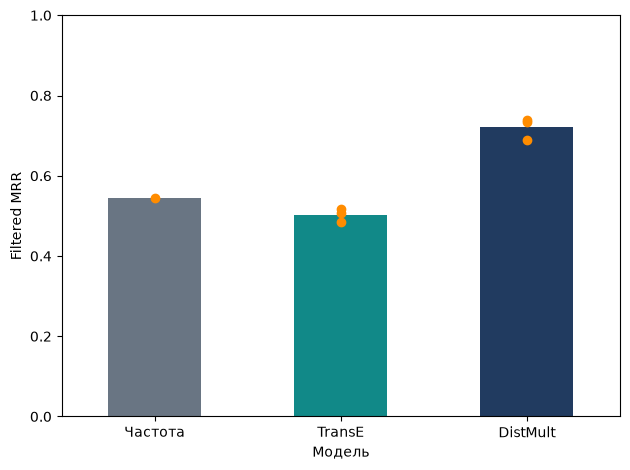

TransE: средняя MRR 0.503; разность с частотой -0.041.
DistMult: средняя MRR 0.721; разность с частотой +0.177.


In [5]:
test = data['test']
counts = seen.sum(0).float()  # [отношение, объект]
base = metrics(ranking(counts[test[:,1]], test, all_known))
seeds = [11,22,33]
rows = [['Частота',None,*base]]
models = {}
for name in ['TransE','DistMult']:
    for seed in seeds:
        model = fit(name,seed)
        rows.append([name,seed,*metrics(ranking(all_scores(model,test),test,all_known))])
        if seed == seeds[0]:
            models[name] = model

runs = pd.DataFrame(rows,columns=['Модель','seed','MRR','Hits@3'])
avg = runs.groupby('Модель',sort=False)[['MRR','Hits@3']].mean()
display(runs.round(3))
ax = avg.MRR.plot.bar(color=['#697583','#118988','#213b60'], rot=0, ylim=(0,1), ylabel='Filtered MRR')
for i,name in enumerate(avg.index):
    vals = runs.loc[runs['Модель']==name,'MRR']
    ax.scatter([i]*len(vals),vals,color='darkorange',zorder=3)
plt.tight_layout()
plt.show()
for name in models:
    print(f'{name}: средняя MRR {avg.loc[name,"MRR"]:.3f}; разность с частотой {avg.loc[name,"MRR"]-base[0]:+.3f}.')

### Сколько подсказок дают обратные записи?

Для каждой тестовой тройки проверим, встречалась ли в train запись с тем же отношением, но с переставленными странами. Для DistMult такая запись при обучении повышает ровно тот балл, который затем проверяется. Сравним MRR двух групп при одной фиксированной инициализации. В группах могут различаться и сами отношения, поэтому это диагностика, а не оценка причинного эффекта.

In [6]:
h,r,t = test.T
reverse_seen = seen[t,r,h]
groups = {'Есть обратная запись':reverse_seen,'Нет обратной записи':~reverse_seen}
diagnostics = []
for name,model in models.items():
    ranks_test = ranking(all_scores(model,test),test,all_known)
    for group,mask in groups.items():
        diagnostics.append([name,group,int(mask.sum()),metrics(ranks_test[mask])[0]])
print(f'Обратная запись есть для {int(reverse_seen.sum())} из {len(test)} троек. Seed {seeds[0]}.')
display(pd.DataFrame(diagnostics,columns=['Модель','Группа','Запросов','MRR']).round(3))

Обратная запись есть для 106 из 201 троек. Seed 11.


,Модель,Группа,Запросов,MRR
0,TransE,Есть обратная запись,106,0.449
1,TransE,Нет обратной записи,95,0.571
2,DistMult,Есть обратная запись,106,0.857
3,DistMult,Нет обратной записи,95,0.597


## 5. Что модель ответила на один запрос?

Берём первую строку теста с отношением `embassy`, независимо от успеха модели. Таблица показывает один и тот же список DistMult до и после фильтрации. Прочерк означает, что страна уже известна как другой верный ответ. Разница рангов не требует переобучения.

In [7]:
index = frames['test'].index[frames['test'].relation == 'embassy'][0]
q = test[index:index+1]
h,r,t = q[0].tolist()
scores = all_scores(models['DistMult'],q)
hide = all_known[h,r].clone()
hide[t] = False
table = pd.DataFrame({'страна':entities,'балл':scores[0].tolist(),'другой верный':hide.tolist()})
table['raw'] = table['балл'].rank(ascending=False)
table['filtered'] = table['балл'].mask(table['другой верный']).rank(ascending=False)
print(f'Запрос: ({entities[h]}, {relations[r]}, ?). Проверяем {entities[t]}. Seed {seeds[0]}.')
display(table.sort_values('raw').round(3))
raw = table.loc[t,'raw']
filtered = ranking(scores,q,all_known).item()
assert filtered == table.loc[t,'filtered'] and filtered <= raw
print(f'Место {entities[t]}: {raw:g} → {filtered:g}.')
for name,model in models.items():
    with torch.no_grad():
        direct = model(*q[0]).item()
        reverse = model(q[0,2],q[0,1],q[0,0]).item()
    print(f'{name}: прямой балл {direct:.3f}, при перестановке стран {reverse:.3f}.')

Запрос: (china, embassy, ?). Проверяем burma. Seed 11.


,страна,балл,другой верный,raw,filtered
5,india,0.965,True,1.0,NaN
13,ussr,-0.041,True,2.0,NaN
4,egypt,-0.096,True,3.0,NaN
11,uk,-0.516,True,4.0,NaN
9,netherlands,-0.848,True,5.0,NaN
10,poland,-1.041,True,6.0,NaN
3,cuba,-1.480,True,7.0,NaN
12,usa,-1.839,False,8.0,1.0
0,brazil,-2.718,False,9.0,2.0
6,indonesia,-3.203,True,10.0,NaN


Место burma: 12 → 4.
TransE: прямой балл -13.610, при перестановке стран -15.362.
DistMult: прямой балл -3.869, при перестановке стран -3.869.


## Ваш вывод

1. На сколько средняя MRR каждой модели отличается от частотного прогноза? Одинаков ли порядок моделей по Hits@3?
2. Назовите страну, которую фильтр убрал выше цели в примере, если такая есть. Изменился ли балл целевой страны?
3. У какой модели балл при перестановке стран должен совпасть для любого запроса? Обоснуйте формулой.

[Данные Nations в PyKEEN](https://github.com/pykeen/pykeen/tree/2e3944f857a2f8e48c4f18d55649044a7e0f318d/src/pykeen/datasets/nations).